# Monthly rainfall forecast for a basin

Read a basin GeoParquet and prepare monthly rainfall directly with `RainfallForecast`.
This workflow needs only polygon geometry with a CRS: no station metadata, calibration,
discharge series, or SQL login.

First download the chosen initialization, forecast centres and leads with notebook 03.
Those CDS files are shared across basins; this notebook reads them without downloading.
Observed rainfall and climatology use the existing MERGE downloader and cache.

In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import geopandas as gpd

from hydro.rainfall import RainfallForecast

## Configuration and geometry

Set `BASIN_PATH` to your GeoParquet and select the desired polygon rows explicitly
if it contains several basins. All selected rows are treated as one analysis region.
The example uses an existing basin geometry file; its other station files are unused.
The existing clipping helper handles reprojection from the GeoParquet's CRS.

`FORECAST_MONTHS` counts from the month containing `AS_OF_DATE`, including that month.
Use `None` for all remaining downloaded leads. An unavailable horizon raises an error.
`START_MONTH` and `FORECAST_YEAR` identify the CDS initialization, which can precede
the reference month. Defaults use all nine centres from notebook 03.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

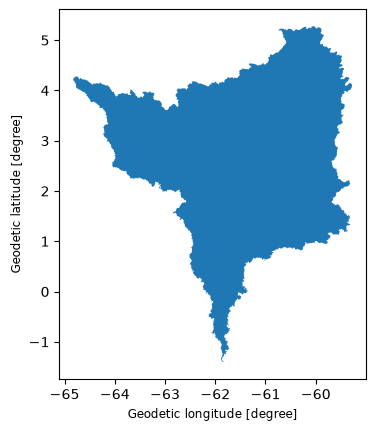

In [5]:
DATA_DIR = Path("/data/CN3S")
BASIN_PATH = Path("/data/tmp/bacia_RioBranco.parquet")
BASIN_NAME = "Rio Branco"
START_MONTH = "10"
FORECAST_YEAR = 2026
AS_OF_DATE = "2026-10-27"
FORECAST_MONTHS = 4

basin = gpd.read_parquet(BASIN_PATH)
basin.plot()


In [6]:
rainfall = RainfallForecast(basin, DATA_DIR, name=BASIN_NAME)

## Prepare basin rainfall

The correction uses the **basin arithmetic mean of grid-cell forecast/hindcast ratios**
and multiplies those ratios by the observed monthly climatology. The corrected values
are calendar-month totals in mm. The stored CDS grids use a fixed 30-day conversion;
that common scale cancels in the forecast/hindcast ratio.

The recent observation window contains 13 preceding months and the reference month.
Current-month observed rainfall can be **partial or cached**; its forecast represents
the whole month. `AS_OF_DATE` selects the calendar window, not a historical data snapshot.

Prepared data remain inspectable as `rainfall.forecast`, `rainfall.rain_observed`,
`rainfall.rain_climatology`, `rainfall.rain_anomaly_pct`, `rainfall.rain_corrected`,
and `rainfall.rain_forecast` (the median across forecast centres).

In [7]:
rainfall.prepare_data(
    start_month=START_MONTH,
    year=FORECAST_YEAR,
    as_of=AS_OF_DATE,
    months=FORECAST_MONTHS,
)

Using HTTP downloads
/usr/local/lib/python3.12/dist-packages/mergedownloader/inpeparser.py:469: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  cube = xr.concat(dependencies[InpeTypes.DAILY_RAIN], dim="time")
/usr/local/lib/python3.12/dist-packages/mergedownloader/inpeparser.py:469: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords 

## Forecast anomaly by model (%)

Percentage anomaly is `100 × (basin mean of forecast/hindcast ratios − 1)`.
Each bar represents one forecast centre for one month.

In [8]:
rainfall.plot_rainfall_anomaly()

## Forecast rainfall, observations and model distribution

Climatology, observations, corrected forecast median, and one boxplot per forecast
month, in mm. Each box contains **one corrected ensemble-mean value per centre**;
it shows spread across models, not across their individual ensemble members.

In [9]:
rainfall.plot_forecast_rainfall().show()

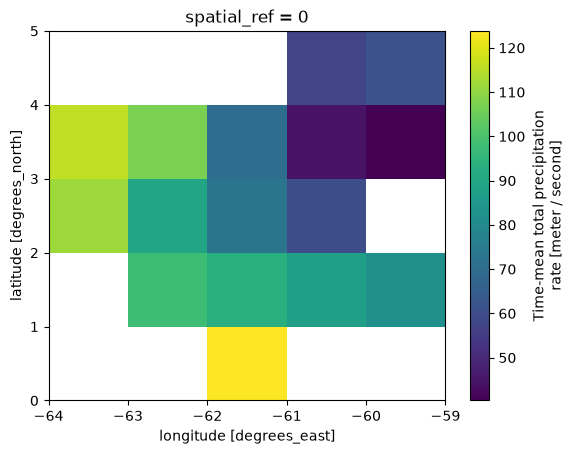

In [18]:
rainfall.forecast.mean(dim=["time", "model"])["hindcast"].plot()

In [19]:
dir(rainfall)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 'as_of',
 'basin',
 'correct_rainfall',
 'data_dir',
 'forecast',
 'forecast_months',
 'forecast_start',
 'name',
 'plot_forecast_rainfall',
 'plot_rainfall_anomaly',
 'plot_raw_rainfall',
 'prepare_data',
 'rain_anomaly_pct',
 'rain_climatology',
 'rain_corrected',
 'rain_forecast',
 'rain_observed']

In [20]:
rainfall.rain_climatology

<xarray.DataArray 'precacum' (time: 17)> Size: 136B
array([ 96.08073194,  70.44198929,  69.15780183,  62.41227118,
        52.28038065,  46.86722831,  71.21910527, 167.42393462,
       288.5021213 , 274.15019115, 243.64608003, 159.82339012,
        96.08073194,  70.44198929,  69.15780183,  62.41227118,
        52.28038065])
Coordinates:
  * time         (time) datetime64[ns] 136B 2025-09-01 2025-10-01 ... 2027-01-01
    spatial_ref  int64 8B 0